# LTUs Connected to Every Input

> **Overview.** LTUs connected to every input, with every weight at 0 and a tiny step-size except a few chosen
> connections with a large one: do the useful connections' step-sizes grow on their own, as growth did in 04c?

In `04c_growing_features.ipynb`, LTUs that start from a few inputs grow into their target LTU's full input set by
connecting the input whose gradient stands out. Reading those gradients costs as much as connecting every input, so
here every LTU is connected to every input instead, and Autostep is left to find the useful connections: their
gradients are consistent, so their step-sizes should grow, while the distractors' gradients are noise. No connection is
ever cut.

**Problem.** As in `04c_growing_features.ipynb`: $N = 1000$ standard normal inputs, and the target is
$\frac{1}{\sqrt{8}} \sum_{k=1}^{8} \mathrm{sign}(w_k \cdot x_k)$ plus $N(0, 0.1^2)$ noise, where target LTU $k$ reads
$x_k$, the $k$-th block of 10 inputs, with random $\pm 1$ weights $w_k$. The best possible RMSE is 0.1 (dotted line),
and the best linear learner's about 0.61 (dashed line). Each seed has its own target weights.

**Learner.** As in `04c_growing_features.ipynb`: the linear learner, a bias, and 32 hidden LTUs (sigmoid derivative
backward) with fixed shadow output weights, +1 and -1 alternately, standardized online; network Autostep
(`squared_inputs`, initial step-size $10^{-4}$, meta step-size 0.02, $\tau = 10^4$). The linear learner learns alone for
the first 100k steps; then the LTUs are added and everything learns for 500k more steps. Each LTU reads every input and
a bias. When the LTUs are added, a few *chosen connections* per LTU get LeCun uniform magnitudes over their number,
with the signs of the linear learner's weights times the LTU's shadow weight, and step-size 0.1; every other input
weight starts at 0 with step-size $10^{-6}$.

**Runs.** 5 seeds per configuration; the same seed gives every run the same samples and target weights. Each pair of
LTUs is assigned one target LTU. The chosen connections are either 4 of the assigned target LTU's inputs, drawn at
random, or 10 inputs drawn without replacement with probability proportional to the square of the linear learner's
weight on each. *Only the target LTU's 10 inputs* (reference): each LTU reads only its target LTU's inputs, all of them
chosen. *Linear learner* (baseline): no LTUs. Curves are the mean over seeds of the RMSE averaged over windows of 1k
steps; final performance is the RMSE over the last 10% of steps. The step-sizes and weights are pooled over every LTU
and seed in four groups of each LTU's input connections: its chosen ones; the other inputs of its *main target LTU*,
the one whose inputs carry the most of its squared input weight at the end (the useful ones); the other target LTUs'
inputs; and the distractors.

In [8]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

In [ ]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # each target LTU reads its own block of N_SOURCES inputs, from the first
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs, each pair reading one target LTU's inputs
CHOSEN_STEP_SIZE = 0.1               # initial step-size of the LTUs' chosen input connections
ZERO_STEP_SIZE = 1e-6                # initial step-size of their other input connections, which start at 0

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 500_000                  # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
SNAPSHOT = 10_000                    # steps per recorded snapshot of the LTUs' input weights and step-sizes
N_SEEDS = 5

## Learner

In [10]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the output's weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the output's connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot


RIGHT, SAMPLED, REFERENCE = 0, 1, 2  # an LTU's chosen connections: some of its target LTU's inputs, inputs sampled
                                     # by the linear learner's weights, or all of its target LTU's inputs, read alone


def own_inputs(slots):
    # Each hidden unit's assigned target LTU's inputs, each pair of units assigned one target LTU in turn.
    return jnp.arange(N_INPUTS) // N_SOURCES == (jnp.arange(slots) // 2 % N_TARGETS)[:, None]


def init_net(units, slots, kind):
    # `units` hidden units in `slots` slots, the rest left empty, reading every input and the bias (REFERENCE: only
    # their target LTU's inputs and the bias); their shadow weights +1 and -1 alternately; every weight at 0.
    reads = jnp.append(own_inputs(slots) | (kind != REFERENCE), jnp.ones((slots, 1), bool), axis=1)
    shadow = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    mask = jnp.concatenate([jnp.ones(N_INPUTS, bool), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': jnp.zeros((slots, N_INPUTS + 1)),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow)


def add_units(net, key, kind, chosen):
    # Each hidden unit's chosen input connections at addition: `chosen` of its target LTU's inputs drawn at random
    # (RIGHT), `chosen` inputs drawn without replacement with probability proportional to the square of the linear
    # learner's weight on them (SAMPLED; Gumbel top-k), or all its target LTU's inputs (REFERENCE). Their weights start
    # with LeCun uniform magnitudes over `chosen` and the signs of the linear learner's weights times the unit's shadow
    # weight, with step-size CHOSEN_STEP_SIZE; every other input weight stays at 0 with step-size ZERO_STEP_SIZE.
    # Returns the network and the chosen connections, shaped (slots, N_INPUTS).
    slots = len(net.shadow)
    draw_key, w_key = jax.random.split(key)
    linear = net.w['output'][0, :N_INPUTS]
    gumbel = jax.random.gumbel(draw_key, (slots, N_INPUTS))
    scores = jnp.where(kind == SAMPLED, jnp.log(linear ** 2) + gumbel, jnp.where(own_inputs(slots), gumbel, -jnp.inf))
    picked = jnp.argsort(jnp.argsort(-scores)) < chosen
    magnitude = jax.random.uniform(w_key, (slots, N_INPUTS)) * jnp.sqrt(3.0 / chosen)
    hidden = jnp.where(picked, magnitude * jnp.sign(net.shadow[:, None] * linear), 0.0)
    beta = jnp.log(jnp.where(picked, CHOSEN_STEP_SIZE, ZERO_STEP_SIZE))
    return net._replace(w={**net.w, 'hidden': net.w['hidden'].at[:, :N_INPUTS].set(hidden)},
                        opt=net.opt._replace(beta={**net.opt.beta,
                                                   'hidden': net.opt.beta['hidden'].at[:, :N_INPUTS].set(beta)})), picked


def learn(net, x, y):
    # One online network-Autostep update on half the squared error, each shadow weight standing in for its hidden
    # unit's output weight in the backward pass while the real one is smaller in magnitude. Returns the new network and
    # the squared error on this sample, before learning from it. `probe` is zero; its gradient is the error arriving at
    # each hidden unit.
    units = len(net.shadow)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0))
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        through_back = jnp.sum(jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1] * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(units))
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats), 2 * loss

## Training

In [11]:
def train(net, key, kind, chosen, add_step, num_steps):
    # num_steps online network-Autostep steps on targets from this seed's target LTUs, the hidden units added at
    # add_step with their chosen connections. Returns each window's mean squared error, the hidden units' input weight
    # magnitudes and step-sizes every SNAPSHOT steps after add_step, and their chosen connections.
    target_key, key = jax.random.split(key)
    target_w = jax.random.rademacher(target_key, (N_TARGETS, N_SOURCES), dtype=float)

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        blocks = x[:target_w.size].reshape(target_w.shape)
        y = (jnp.sum(jnp.where(jnp.sum(target_w * blocks, 1) > 0, 1.0, -1.0)) / np.sqrt(N_TARGETS)
             + NOISE_STD * jax.random.normal(noise_key, (1,)))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        return learn(net, x, y)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        return net, mse.mean()

    def snapshot(net, inputs):
        net, mse = jax.lax.scan(window, net, inputs)
        return net, (mse, jnp.abs(net.w['hidden'][:, :N_INPUTS]), jnp.exp(net.opt.beta['hidden'][:, :N_INPUTS]))

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net, picked = add_units(net, jax.random.fold_in(target_key, 1), kind, chosen)
    blocks = lambda a: a[added:].reshape(-1, SNAPSHOT // WINDOW, *a.shape[1:])   # windows per snapshot
    after, w, alpha = jax.lax.scan(snapshot, net, (blocks(index), blocks(keys)))[1]
    return jnp.concatenate([before, after.reshape(-1)]), w, alpha, picked


def run(units, configs):
    # Each (kind, chosen) of configs: `units` hidden LTUs (none: the linear learner alone) with chosen connections of
    # that kind and number, each on N_SEEDS seeds, vmapped together. Seed s gives every run the same samples and target
    # weights. Returns, each as {config: array}, the RMSE of each window from step 1 (seed, window), the LTUs' input
    # weight magnitudes and step-sizes every SNAPSHOT steps after they are added (seed, snapshot, LTU, input), and their
    # chosen connections (seed, LTU, input).
    kind, chosen, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = jax.random.split(jax.random.PRNGKey(1), N_SEEDS)[seed]
    nets = jax.vmap(lambda i: init_net(units, max(units, 1), i))(kind)
    train_all = jax.jit(jax.vmap(lambda n, k, i, c: train(n, k, i, c, LINEAR_STEPS, LINEAR_STEPS + NUM_STEPS)))
    mse, w, alpha, picked = train_all(nets, keys, kind, chosen)
    by_config = lambda a: dict(zip(configs, np.asarray(a).reshape(len(configs), N_SEEDS, *a.shape[1:])))
    return by_config(np.sqrt(mse)), by_config(w), by_config(alpha), by_config(picked)

## Runs

In [12]:
CONFIGS = {"4 of the target LTU's inputs chosen": (RIGHT, 4),
           "10 inputs sampled by the linear learner's weights chosen": (SAMPLED, 10)}
REFERENCE_CONFIG = (REFERENCE, N_SOURCES)
started = perf_counter()
linear = run(0, [REFERENCE_CONFIG])[0][REFERENCE_CONFIG]
rmse, weights, step_sizes, chosen = run(N_LTUS, [REFERENCE_CONFIG, *CONFIGS.values()])
print(f'{(len(rmse) + 1) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

20 runs in 43s


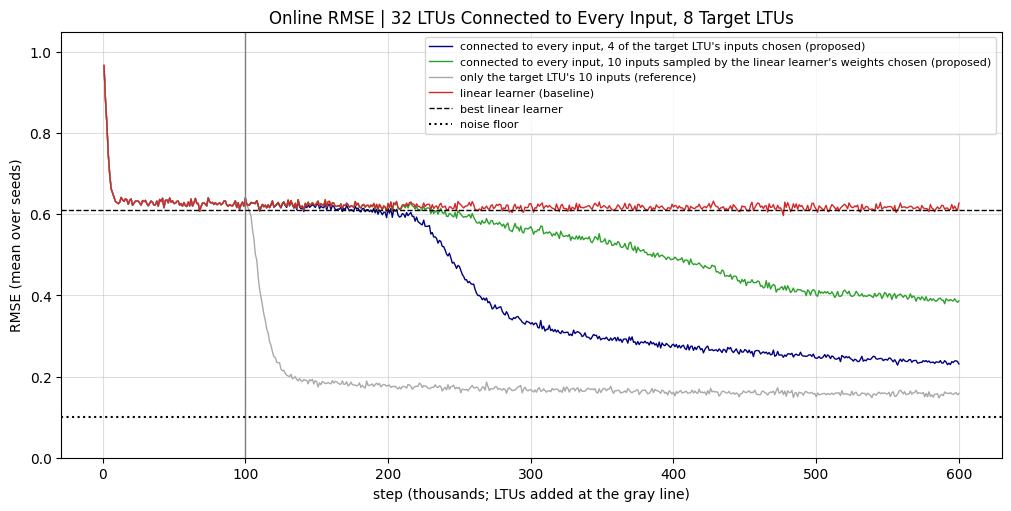

In [13]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
for (label, config), color in zip(CONFIGS.items(), ['navy', 'tab:green']):
    ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1, label=f'connected to every input, {label} (proposed)')
ax.plot(STEPS / 1000, rmse[REFERENCE_CONFIG].mean(0), color='darkgray', lw=1,
        label="only the target LTU's 10 inputs (reference)")
ax.plot(STEPS / 1000, linear.mean(0), color='tab:red', lw=1, label='linear learner (baseline)')
ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE (mean over seeds)', ylim=(0, 1.05),
       title=f'Online RMSE | {N_LTUS} LTUs Connected to Every Input, {N_TARGETS} Target LTUs')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

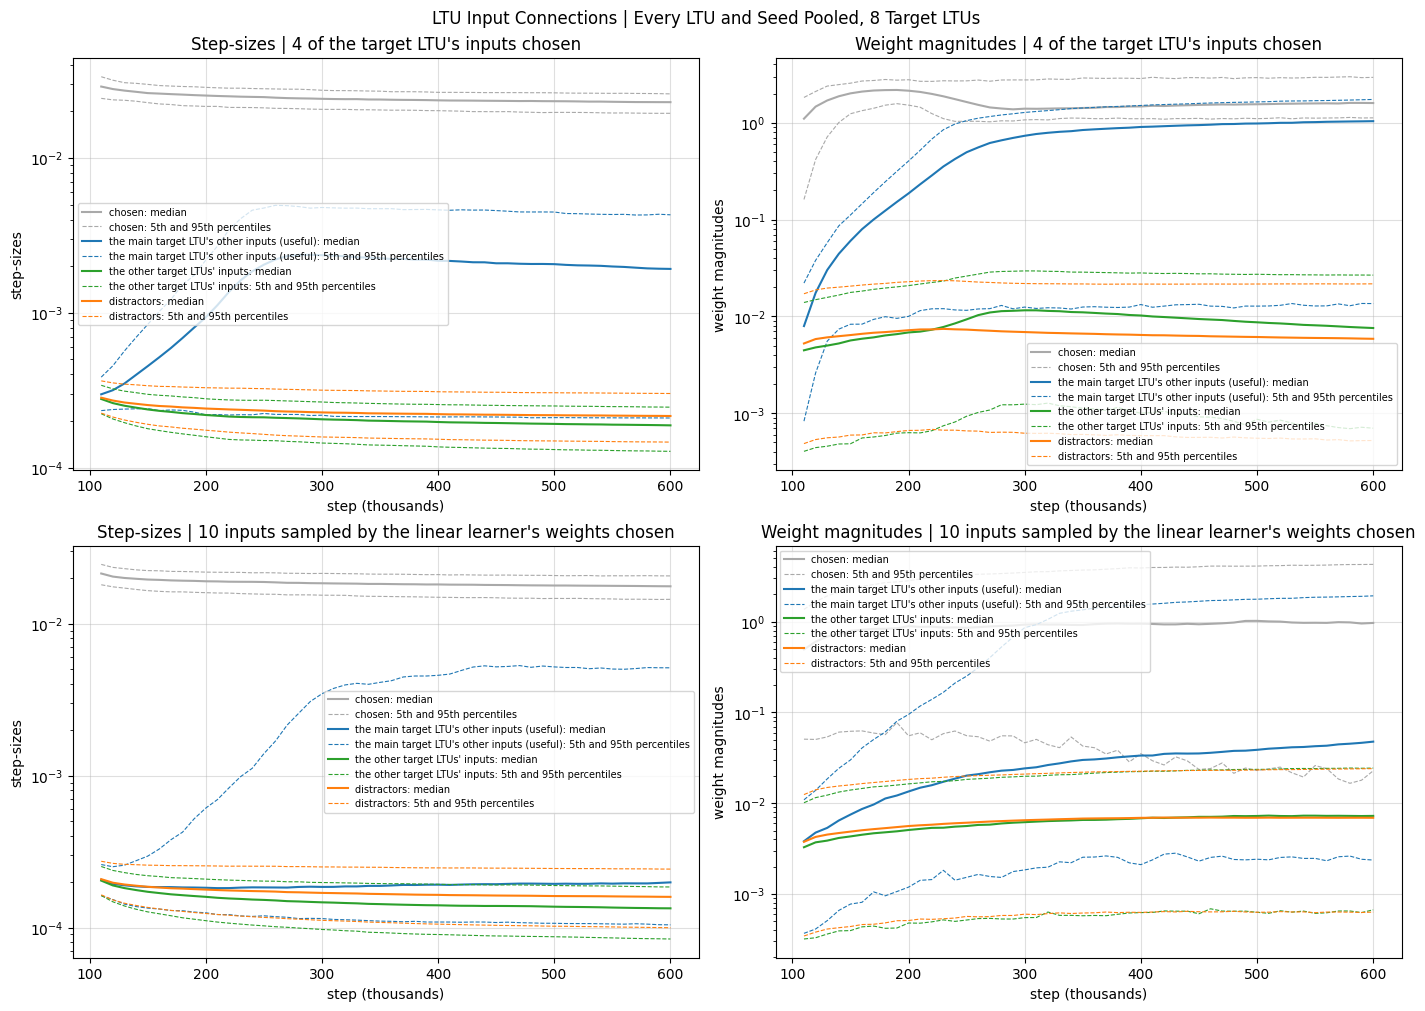

In [14]:
SNAPSHOT_STEPS = LINEAR_STEPS + (np.arange(NUM_STEPS // SNAPSHOT) + 1) * SNAPSHOT
block = np.arange(N_INPUTS) // N_SOURCES     # the target LTU that reads each input (N_TARGETS and up: none)


def groups(config):
    # Each group of every LTU's input connections, as masks shaped (seed, LTU, input). An LTU's main target LTU is the
    # one whose inputs carry the most of its squared input weight at the end.
    squared = weights[config][:, -1] ** 2
    main = np.stack([squared[..., block == k].sum(-1) for k in range(N_TARGETS)], -1).argmax(-1)
    in_main = block == main[..., None]
    picked = chosen[config]
    return {'chosen': picked, "the main target LTU's other inputs (useful)": in_main & ~picked,
            "the other target LTUs' inputs": (block < N_TARGETS) & ~in_main & ~picked,
            'distractors': (block >= N_TARGETS) & ~picked}


fig, axes = plt.subplots(len(CONFIGS), 2, figsize=(14, 5 * len(CONFIGS)), layout='constrained')
for row, (label, config) in zip(axes, CONFIGS.items()):
    for ax, (name, values) in zip(row, {'Step-sizes': step_sizes, 'Weight magnitudes': weights}.items()):
        by_snapshot = np.moveaxis(values[config], 1, 0)     # (snapshot, seed, LTU, input)
        for (group, mask), color in zip(groups(config).items(), ['darkgray', 'tab:blue', 'tab:green', 'tab:orange']):
            low, median, high = np.percentile(by_snapshot[:, mask], [5, 50, 95], axis=1)
            ax.plot(SNAPSHOT_STEPS / 1000, median, color=color, label=f'{group}: median')
            ax.plot(SNAPSHOT_STEPS / 1000, low, color=color, ls='--', lw=0.8, label=f'{group}: 5th and 95th percentiles')
            ax.plot(SNAPSHOT_STEPS / 1000, high, color=color, ls='--', lw=0.8)
        ax.set(xlabel='step (thousands)', ylabel=name.lower(), yscale='log', title=f'{name} | {label}')
        ax.grid(alpha=0.4)
        ax.legend(fontsize=7)
fig.suptitle(f'LTU Input Connections | Every LTU and Seed Pooled, {N_TARGETS} Target LTUs')
plt.show()

## Results

5 seeds per configuration. The notebook takes about 1 minute.

- **The useful connections' step-sizes grow on their own.** With 4 of the target LTU's inputs chosen, the step-sizes of
  its other 6 inputs grow from $10^{-6}$ to about $2 \times 10^{-3}$ over the first 300k steps after the LTUs are added,
  and their weights to about 0.6, while the step-sizes of the other target LTUs' inputs and the distractors fall to
  about $2 \times 10^{-7}$ and their weights stay near $10^{-5}$. The LTUs end at RMSE 0.20, reaching 0.2 in a median
  400k steps: slower than growing in `04c_growing_features.ipynb` (0.15, in 137k).
- **From 10 sampled inputs this mostly fails**: the useful step-sizes grow in only some LTUs (the 95th percentile
  reaches $5 \times 10^{-3}$, the median $3 \times 10^{-6}$), and the LTUs end at 0.52, against 0.19 with growth in
  `04c_growing_features.ipynb`.